# Actividad 1 — Regresión lineal y árboles de decisión para tareas de regresión
**Técnicas de Aprendizaje Automático · Máster Universitario en Inteligencia Artificial**  
**Entrega académica · Análisis y modelado de calidad del aire**  
**Dataset:** Air Quality (UCI Machine Learning Repository) · **Variable respuesta:** `CO(GT)`

## Objetivos y metodología
Se realiza un análisis exploratorio, tratamiento de valores faltantes, regresión lineal simple y múltiple, regresión con árbol de decisión y comparación mediante métricas comunes. El estudio predice la concentración de CO de la **misma observación horaria** a partir de otras mediciones disponibles; no constituye por sí solo una predicción futura por día. Se utiliza una división aleatoria reproducible, por lo que las métricas reflejan generalización a observaciones retenidas y no una validación temporal.

## 1. Análisis descriptivo de los datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
pd.set_option('display.max_columns', 30)
archivo = 'AirQualityUCI.csv'
df = pd.read_csv(archivo, sep=';', decimal=',')
df = df.dropna(axis=1, how='all').dropna(axis=0, how='all').copy()
print('Dimensiones:', df.shape)
display(df.head())

Dimensiones: (9357, 15)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


### 1.1 ¿Cuántas instancias tiene el dataset?

In [2]:
print(f'Instancias: {len(df):,}; columnas: {df.shape[1]}')

Instancias: 9,357; columnas: 15


**Respuesta.** El archivo suministrado contiene **9357 instancias y 15 columnas** después de eliminar filas y columnas completamente vacías. Cada instancia corresponde a una medición horaria. La descripción del repositorio UCI informa 9358 instancias; para este entregable se reporta el conteo del archivo efectivamente recibido.

### 1.2 ¿Cuál es el tipo de datos de cada columna?

In [3]:
display(df.dtypes.rename("Tipo de dato").to_frame())

,Tipo de dato
Date,object
Time,object
CO(GT),float64
PT08.S1(CO),float64
NMHC(GT),float64
C6H6(GT),float64
PT08.S2(NMHC),float64
NOx(GT),float64
PT08.S3(NOx),float64
NO2(GT),float64


**Respuesta.** `Date` y `Time` son cadenas (`object`) que codifican fecha y hora; las otras 13 columnas son numéricas (`float64`). La clasificación técnica del tipo no debe confundirse con la naturaleza semántica: fecha y hora son variables temporales.

### 1.3 ¿Cuántas columnas categóricas y continuas hay?

In [4]:
texto = df.select_dtypes(include=['object','category']).columns.tolist()
numericas = df.select_dtypes(include='number').columns.tolist()
print('Columnas tipo texto:',len(texto), texto)
print('Columnas numéricas:',len(numericas), numericas)

Columnas tipo texto: 2 ['Date', 'Time']
Columnas numéricas: 13 ['CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']


**Respuesta.** Hay **2 columnas de texto/temporales** (`Date`, `Time`) y **13 variables numéricas**. No se identifican variables categóricas nominales propiamente dichas. Las 13 numéricas se tratan como variables cuantitativas de medición o respuesta de sensores.

### 1.4 ¿Existen valores nulos?

In [5]:
print('Nulos originales:')
display(df.isna().sum().to_frame('Nulos'))
num_cols = df.select_dtypes(include='number').columns
df[num_cols] = df[num_cols].replace(-200, np.nan)
print('Nulos tras reconocer -200:')
display(df.isna().sum().to_frame('Nulos'))
print('Filas con al menos un dato ausente:',df.isna().any(axis=1).sum())

Nulos originales:


,Nulos
Date,0
Time,0
CO(GT),0
PT08.S1(CO),0
NMHC(GT),0
C6H6(GT),0
PT08.S2(NMHC),0
NOx(GT),0
PT08.S3(NOx),0
NO2(GT),0


Nulos tras reconocer -200:


,Nulos
Date,0
Time,0
CO(GT),1683
PT08.S1(CO),366
NMHC(GT),8443
C6H6(GT),366
PT08.S2(NMHC),366
NOx(GT),1639
PT08.S3(NOx),366
NO2(GT),1642


Filas con al menos un dato ausente: 8530


**Respuesta.** El código original puede no detectar valores ausentes porque el dataset codifica mediciones no disponibles mediante **−200**. Tras sustituir ese marcador por `NaN`, se obtiene el conteo real por variable. La imputación se realizará **después de separar entrenamiento y prueba**, para evitar fuga de información.

### 1.5 ¿Cuál es la variable respuesta y de qué tipo es?

In [6]:
objetivo = 'CO(GT)'
print(objetivo, df[objetivo].dtype, 'observaciones válidas:',df[objetivo].notna().sum())

CO(GT) float64 observaciones válidas: 7674


**Respuesta.** Se elige `CO(GT)`, concentración de monóxido de carbono (mg/m³), como variable **cuantitativa continua**. Es una medición de referencia con interés ambiental y admite predicción mediante regresión. Las filas sin objetivo conocido no pueden emplearse en el entrenamiento supervisado.

### 1.6 ¿Cómo se distribuyen CO, NOx y NO2? ¿Hay anomalías?

,count,mean,std,min,25%,50%,75%,max
CO(GT),7674.0,2.153,1.453,0.1,1.1,1.8,2.9,11.9
NOx(GT),7718.0,246.897,212.979,2.0,98.0,180.0,326.0,1479.0
NO2(GT),7715.0,113.091,48.370,2.0,78.0,109.0,142.0,340.0


,median,skew
CO(GT),1.8,1.370
NOx(GT),180.0,1.716
NO2(GT),109.0,0.622


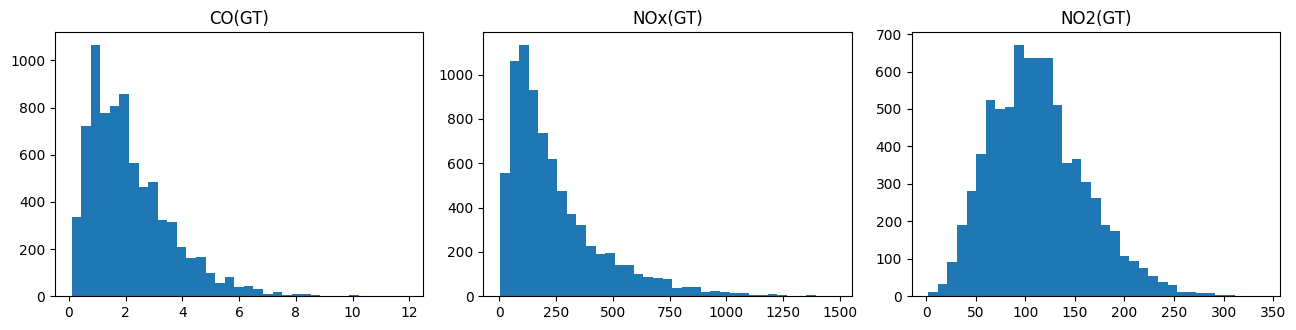

CO(GT): ausentes=1683, atípicos IQR=215, sesgo=1.370
NOx(GT): ausentes=1639, atípicos IQR=435, sesgo=1.716
NO2(GT): ausentes=1642, atípicos IQR=107, sesgo=0.622


In [7]:
contaminantes=['CO(GT)','NOx(GT)','NO2(GT)']
display(df[contaminantes].describe().T.round(3))
display(df[contaminantes].agg(['median','skew']).T.round(3))
fig, axs = plt.subplots(1,3,figsize=(13,3.4))
for ax,col in zip(axs,contaminantes):
    ax.hist(df[col].dropna(),bins=35)
    ax.set_title(col)
plt.tight_layout(); plt.show()
for col in contaminantes:
    s=df[col].dropna(); q1,q3=s.quantile([.25,.75]);iqr=q3-q1
    print(f'{col}: ausentes={df[col].isna().sum()}, atípicos IQR={((s<q1-1.5*iqr)|(s>q3+1.5*iqr)).sum()}, sesgo={s.skew():.3f}')

**Interpretación.** Se comparan media, mediana y asimetría, además de los histogramas. Los contaminantes muestran concentraciones no negativas y colas hacia valores elevados; los puntos señalados por la regla IQR son **posibles valores extremos**, no necesariamente errores, pues pueden reflejar episodios reales de contaminación. Hay ausencias marcadas con −200 que deben tratarse. La distribución no debe suponerse normal sin pruebas adicionales.

### 1.7 ¿Cómo son las correlaciones?

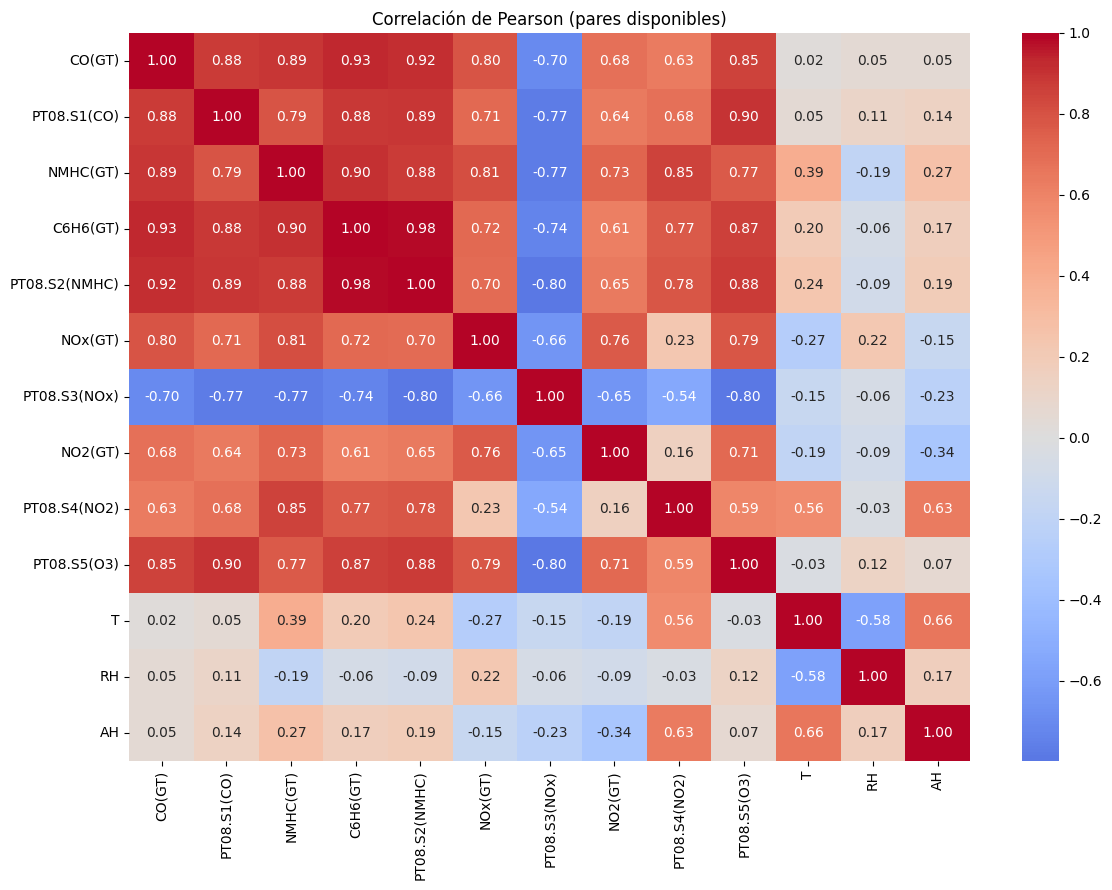

In [8]:
correlacion=df.select_dtypes(include='number').corr()
plt.figure(figsize=(12,9))
sns.heatmap(correlacion,annot=True,fmt='.2f',cmap='coolwarm',center=0)
plt.title('Correlación de Pearson (pares disponibles)');plt.tight_layout();plt.show()

**Respuesta.** La matriz de Pearson permite identificar asociaciones lineales positivas y negativas entre sensores, contaminantes y meteorología. Correlación no implica causalidad; además, valores próximos a cero solo descartan una asociación *lineal* fuerte, no relaciones no lineales.

### 1.8 ¿Qué tres variables se correlacionan más con el objetivo?

In [9]:
corr_obj=correlacion[objetivo].drop(index=objetivo).dropna()
top_3=corr_obj.abs().nlargest(3)
display(pd.DataFrame({'Correlación de Pearson':corr_obj.loc[top_3.index], 'Magnitud absoluta':top_3}))

,Correlación de Pearson,Magnitud absoluta
C6H6(GT),0.931078,0.931078
PT08.S2(NMHC),0.915514,0.915514
NMHC(GT),0.889734,0.889734


**Respuesta.** Las tres variables aparecen en la tabla anterior, ordenadas por **valor absoluto** del coeficiente. El signo original indica si la relación es directa o inversa. Para elegir el predictor del modelo simple se recalculará la correlación **solo con los datos de entrenamiento**, evitando utilizar información del conjunto de prueba en la selección.

### 1.9 ¿Existe alguna variable sin correlación?

In [10]:
display(corr_obj.reindex(corr_obj.abs().sort_values().index).head(5).to_frame("Pearson con CO(GT)"))

,Pearson con CO(GT)
T,0.022109
AH,0.048556
RH,0.048890
PT08.S4(NO2),0.630703
NO2(GT),0.683343


**Respuesta.** Las variables mostradas son las de **menor correlación lineal absoluta** con CO. Un coeficiente cercano a cero no significa independencia estadística ni ausencia total de utilidad predictiva.

### 1.10 Conclusiones del EDA y decisiones de modelado

**Síntesis.** (1) Los marcadores −200 se convierten en ausencias; (2) se eliminan las filas sin `CO(GT)` y se imputan predictores a partir del entrenamiento; (3) las señales de sensores y otras mediciones pueden aportar capacidad predictiva; (4) se compararán relaciones lineales y no lineales; (5) se conservará el mismo conjunto de prueba para todos los modelos. `Date` y `Time` se excluyen de la regresión múltiple porque son texto y requerirían una ingeniería de características temporal explícita. **Limitación:** las mediciones simultáneas de otros contaminantes no equivalen a una predicción anticipada y la partición aleatoria puede sobreestimar el rendimiento en series temporales.

## 2. Preparación para la regresión

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_log_error

model_df=df.dropna(subset=[objetivo]).copy()
X=model_df.select_dtypes(include='number').drop(columns=[objetivo])
y=model_df[objetivo]
X_train_raw,X_test_raw,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=42)
imputador=SimpleImputer(strategy='median')
X_train=pd.DataFrame(imputador.fit_transform(X_train_raw),columns=X.columns,index=X_train_raw.index)
X_test=pd.DataFrame(imputador.transform(X_test_raw),columns=X.columns,index=X_test_raw.index)
escalador=StandardScaler()
X_train_scaled=pd.DataFrame(escalador.fit_transform(X_train),columns=X.columns,index=X_train.index)
X_test_scaled=pd.DataFrame(escalador.transform(X_test),columns=X.columns,index=X_test.index)
print('Entrenamiento:',X_train.shape,'Prueba:',X_test.shape)
print('Ausencias tras imputación:',int(X_train.isna().sum().sum()+X_test.isna().sum().sum()))

Entrenamiento: (6139, 12) Prueba: (1535, 12)
Ausencias tras imputación: 0


### 2.1 Regresión lineal simple: selección y entrenamiento

In [12]:
corr_train=X_train_raw.corrwith(y_train).dropna()
variable_simple=corr_train.abs().idxmax()
modelo_simple=LinearRegression().fit(X_train_scaled[[variable_simple]],y_train)
pred_simple=modelo_simple.predict(X_test_scaled[[variable_simple]])
print('Predictor:',variable_simple)
print('Intercepto:',round(modelo_simple.intercept_,5),'Coeficiente:',round(modelo_simple.coef_[0],5))

Predictor: C6H6(GT)
Intercepto: 2.1663 Coeficiente: 1.30458


**Interpretación de parámetros.** El intercepto representa la concentración de CO estimada cuando el predictor estandarizado vale cero, es decir, cuando toma la media del conjunto de entrenamiento. El coeficiente expresa el cambio esperado en CO (mg/m³) ante un aumento de una desviación estándar del predictor, manteniendo la relación lineal estimada.

### 2.2 Métrica, predicciones y error del modelo simple

In [13]:
mae_simple=mean_absolute_error(y_test,pred_simple)
r2_simple=r2_score(y_test,pred_simple)
print('Primeras predicciones:',np.round(pred_simple[:5],3))
print(f'MAE simple = {mae_simple:.4f} mg/m³; R² = {r2_simple:.4f}')

Primeras predicciones: [1.867 0.871 3.558 2.045 1.298]
MAE simple = 0.4051 mg/m³; R² = 0.7979


**Justificación.** Se elige **MAE** como métrica principal porque expresa el error absoluto promedio en las mismas unidades que el objetivo (mg/m³), facilitando su interpretación. Se complementa con **R²**, que cuantifica el ajuste relativo respecto a predecir la media. El error MAE representa cuánto se desvía, en promedio, la predicción del valor medido; no indica el sentido del error.

### 2.3 Regresión lineal múltiple con todas las variables predictoras numéricas

In [14]:
modelo_multiple=LinearRegression().fit(X_train_scaled,y_train)
pred_multiple=modelo_multiple.predict(X_test_scaled)
mae_multiple=mean_absolute_error(y_test,pred_multiple)
r2_multiple=r2_score(y_test,pred_multiple)
print(f'MAE múltiple = {mae_multiple:.4f} mg/m³; R² = {r2_multiple:.4f}')
print('Diferencia de MAE (múltiple - simple):',round(mae_multiple-mae_simple,4))

MAE múltiple = 0.3000 mg/m³; R² = 0.8931
Diferencia de MAE (múltiple - simple): -0.1052


**Comparación.** El modelo múltiple es mejor en error absoluto si su MAE es menor. Se deben comparar simultáneamente MAE y R²: incorporar más predictores puede captar información adicional, pero también redundancias entre sensores. Los valores anteriores proceden del mismo conjunto de prueba y son comparables.

## 3. Regresión con árboles de decisión

### 3.1 Significado de los hiperparámetros
- **`criterion`**: función que valora la calidad de una partición; `poisson` utiliza la reducción de desviancia de Poisson.
- **`splitter`**: estrategia de búsqueda de la partición en cada nodo (`best` o `random`).
- **`max_depth`**: máxima profundidad del árbol; limita su complejidad.
- **`min_samples_split`**: número mínimo de muestras para dividir un nodo.
- **`min_samples_leaf`**: número mínimo de muestras que debe contener una hoja.
- **`max_features`**: cantidad de variables consideradas al buscar la mejor partición; `None` considera todas.
- **`min_impurity_decrease`**: mejora mínima ponderada de impureza requerida para aceptar una división; valores mayores restringen el crecimiento y pueden reducir sobreajuste.

El enunciado menciona dos modelos de árbol, pero **solo especifica hiperparámetros para uno**. Se incluye además un segundo árbol de referencia con poda preventiva, claramente identificado como comparación adicional.

### 3.2 Árbol requerido: Poisson, profundidad 10

In [15]:
assert y_train.ge(0).all() and y_train.sum()>0, 'Poisson requiere objetivos no negativos y suma positiva'
modelo_arbol=DecisionTreeRegressor(criterion='poisson',max_depth=10,min_samples_split=10,
                                  min_samples_leaf=2,max_features=None,random_state=42)
modelo_arbol.fit(X_train,y_train)
pred_arbol=modelo_arbol.predict(X_test)
mae_arbol=mean_absolute_error(y_test,pred_arbol)
r2_arbol=r2_score(y_test,pred_arbol)
rmsle_arbol=np.sqrt(mean_squared_log_error(y_test,np.maximum(pred_arbol,0)))
print(f'MAE = {mae_arbol:.4f}; R² = {r2_arbol:.4f}; RMSLE = {rmsle_arbol:.4f}')

MAE = 0.2984; R² = 0.8912; RMSLE = 0.1444


**Interpretación de métricas.** MAE es el error medio absoluto en mg/m³; R² mide el ajuste relativo; RMSLE penaliza las diferencias logarítmicas entre predicciones y valores reales, con sensibilidad a errores relativos. RMSLE requiere observaciones y predicciones no negativas, condición satisfecha para este objetivo y el árbol Poisson.

### 3.3 ¿Existe overfitting?

In [16]:
pred_train_arbol=modelo_arbol.predict(X_train)
mae_train_arbol=mean_absolute_error(y_train,pred_train_arbol)
r2_train_arbol=r2_score(y_train,pred_train_arbol)
print(f'Entrenamiento: MAE={mae_train_arbol:.4f}; R²={r2_train_arbol:.4f}')
print(f'Prueba:        MAE={mae_arbol:.4f}; R²={r2_arbol:.4f}')
print(f'Brecha MAE prueba-entrenamiento: {mae_arbol-mae_train_arbol:.4f}')

Entrenamiento: MAE=0.2073; R²=0.9527
Prueba:        MAE=0.2984; R²=0.8912
Brecha MAE prueba-entrenamiento: 0.0911


**Respuesta.** Se evalúa el sobreajuste comparando el error en entrenamiento y prueba. Si el MAE de entrenamiento es sustancialmente menor que el de prueba y el R² cae en prueba, hay indicios de sobreajuste. La magnitud de esa diferencia debe interpretarse en contexto; una validación cruzada y, por tratarse de datos horarios, una validación cronológica aportan evidencia adicional.

### 3.4 Segundo árbol (comparación complementaria con mayor regularización)

In [17]:
modelo_arbol_regularizado=DecisionTreeRegressor(criterion='poisson',max_depth=5,
    min_samples_split=20,min_samples_leaf=10,max_features=None,random_state=42)
modelo_arbol_regularizado.fit(X_train,y_train)
pred_arbol_regularizado=modelo_arbol_regularizado.predict(X_test)
mae_arbol_regularizado=mean_absolute_error(y_test,pred_arbol_regularizado)
r2_arbol_regularizado=r2_score(y_test,pred_arbol_regularizado)
rmsle_arbol_regularizado=np.sqrt(mean_squared_log_error(y_test,np.maximum(pred_arbol_regularizado,0)))
print(f'Árbol regularizado: MAE={mae_arbol_regularizado:.4f}; R²={r2_arbol_regularizado:.4f}; RMSLE={rmsle_arbol_regularizado:.4f}')

Árbol regularizado: MAE=0.3385; R²=0.8766; RMSLE=0.1559


**Análisis.** El segundo árbol reduce la profundidad y aumenta los mínimos de muestras para limitar su complejidad. Su rendimiento se compara sin alterar el conjunto de prueba. Esta variante es una decisión metodológica complementaria, no una configuración impuesta por el enunciado.

## 4. Comparativa final y conclusiones

,Modelo,MAE (mg/m³),R²
0,Árbol Poisson (requerido),0.2984,0.8912
1,Regresión lineal múltiple,0.3000,0.8931
2,Árbol Poisson (regularizado),0.3385,0.8766
3,Regresión lineal simple,0.4051,0.7979


Mejor modelo por MAE: Árbol Poisson (requerido)


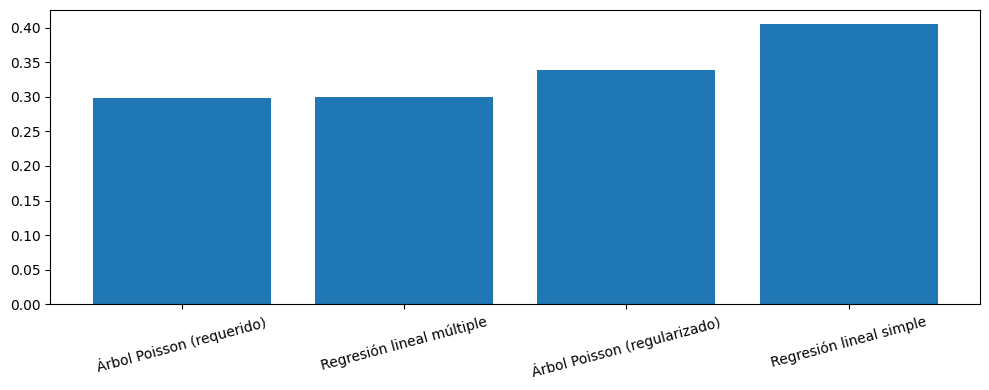

In [18]:
resultados=pd.DataFrame({
 'Modelo':['Regresión lineal simple','Regresión lineal múltiple','Árbol Poisson (requerido)','Árbol Poisson (regularizado)'],
 'MAE (mg/m³)':[mae_simple,mae_multiple,mae_arbol,mae_arbol_regularizado],
 'R²':[r2_simple,r2_multiple,r2_arbol,r2_arbol_regularizado]})
resultados=resultados.sort_values('MAE (mg/m³)').reset_index(drop=True)
display(resultados.round(4))
print('Mejor modelo por MAE:',resultados.loc[0,'Modelo'])
fig,ax=plt.subplots(figsize=(10,4))
ax.bar(resultados['Modelo'],resultados['MAE (mg/m³)'])
ax.tick_params(axis='x',rotation=15);plt.tight_layout();plt.show()

In [19]:
ganador=resultados.iloc[0]
print(f"CONCLUSIÓN CUANTITATIVA: el menor MAE de prueba corresponde a {ganador['Modelo']} "
      f"({ganador['MAE (mg/m³)']:.4f} mg/m³; R²={ganador['R²']:.4f}).")
print(f'Brecha del árbol requerido: {mae_arbol-mae_train_arbol:.4f} mg/m³.')

CONCLUSIÓN CUANTITATIVA: el menor MAE de prueba corresponde a Árbol Poisson (requerido) (0.2984 mg/m³; R²=0.8912).
Brecha del árbol requerido: 0.0911 mg/m³.


**Discusión y conclusiones.** La tabla anterior identifica el modelo con menor MAE en el conjunto de prueba, mientras que R² permite contrastar su ajuste. La regresión simple es la alternativa más interpretable y menos costosa; la múltiple aprovecha más mediciones, aunque puede verse afectada por multicolinealidad; el árbol permite relaciones no lineales y umbrales, pero puede sobreajustar. El árbol regularizado ilustra el compromiso entre complejidad y generalización. La selección final se basa en las métricas calculadas, no en una preferencia teórica por una técnica.

**Limitaciones:** el estudio utiliza observaciones horarias, una partición aleatoria y variables simultáneas. Para pronosticar el CO de días futuros, sería necesario crear variables rezagadas y validar con una partición temporal. No se han medido tiempos de ejecución ni especificaciones del equipo, por lo que no se atribuyen diferencias de rendimiento computacional concretas al hardware.

## 5. Investigación: aplicación científica de regresión

**Referencia APA (artículo de revista posterior a 2015):**  
Liu, H., Li, Q., Yu, D., & Gu, Y. (2019). Air quality index and air pollutant concentration prediction based on machine learning algorithms. *Applied Sciences, 9*(19), 4069. https://doi.org/10.3390/app9194069

**Objetivo.** Predecir el índice de calidad del aire (AQI) en Pekín y la concentración de óxidos de nitrógeno (NOx) en una ciudad italiana, para apoyar el seguimiento de la contaminación atmosférica.

**Técnicas y adaptaciones.** Los autores comparan *support vector regression* (SVR) y *random forest regression* (RFR). RFR es un conjunto de árboles de decisión para regresión; en lugar de un único árbol, combina múltiples árboles. El artículo no requiere técnicas de aprendizaje profundo.

**Resultados principales.** SVR obtuvo mejores resultados en la predicción de AQI (RMSE = 7.666; R² = 0.9776; r = 0.9887), mientras que RFR destacó en NOx (RMSE = 83.6716; R² = 0.8401; r = 0.9180). Estos resultados son **del artículo**, no de los modelos entrenados en este notebook.

**Relación con la actividad.** El estudio muestra que los modelos basados en árboles pueden ser útiles para estimar contaminantes atmosféricos, aunque su rendimiento depende de la variable objetivo y del contexto. Aquí se evalúa un árbol individual y regresiones lineales, no un bosque aleatorio.

**Fuentes:** [Artículo científico](https://www.mdpi.com/2076-3417/9/19/4069) · [Dataset UCI](https://archive.ics.uci.edu/dataset/360/air+quality)

---
**Reproducibilidad:** archivo `AirQualityUCI.csv` en la misma carpeta, bibliotecas `numpy`, `pandas`, `matplotlib`, `seaborn` y `scikit-learn`. Ejecutar las celdas en orden desde el inicio.